# TP2 - Visión por Computadora I

## Detector de máximo enfoque

In [1]:
# Librerías
import cv2 as cv                 # OpenCV: leer el video y procesar imágenes
import numpy as np               # cuentas con matrices
import matplotlib.pyplot as plt  # gráficos
%matplotlib inline

Cantidad de frames: 171
Tamaño de cada frame (alto, ancho, canales): (360, 640, 3)


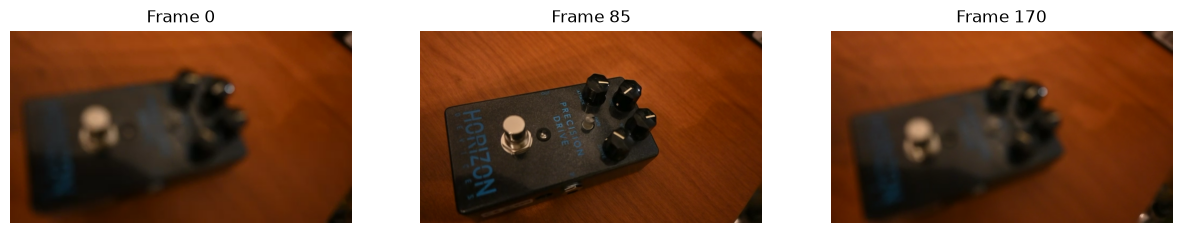

In [2]:
# Abrimos el video
video = cv.VideoCapture('focus_video.mov')

# Leemos todos los frames (cuadros) del video y los guardamos en una lista
frames = []
while True:
    ok, frame = video.read()     # ok = False cuando ya no quedan frames
    if not ok:
        break
    frames.append(frame)
video.release()

print('Cantidad de frames:', len(frames))
print('Tamaño de cada frame (alto, ancho, canales):', frames[0].shape)

# Mostramos 3 frames: el primero, uno del medio y el último
elegidos = [0, len(frames) // 2, len(frames) - 1]
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, i in zip(ejes, elegidos):
    eje.imshow(cv.cvtColor(frames[i], cv.COLOR_BGR2RGB))   # BGR -> RGB para mostrar bien los colores
    eje.set_title(f'Frame {i}')
    eje.axis('off')
plt.show()

In [3]:
def medida_enfoque(img_bgr):
    """Métrica del paper: fracción de frecuencias con peso 'no despreciable'. Más alta = más nítida."""
    # 1) Pasamos a gris: la nitidez no depende del color
    gris = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY).astype(np.float32)
    # 2) Transformada de Fourier, centrada (fftshift) y en valor absoluto (cuánto pesa cada frecuencia)
    espectro = np.abs(np.fft.fftshift(np.fft.fft2(gris)))
    # 3) Umbral: el valor más grande del espectro dividido 1000
    umbral = espectro.max() / 1000
    # 4) Contamos cuántas frecuencias lo superan y lo pasamos a fracción del total
    return (espectro > umbral).sum() / gris.size

# Probamos con los 3 frames de antes
for i in elegidos:
    print(f'Frame {i}: medida de enfoque = {medida_enfoque(frames[i]):.4f}')


Frame 0: medida de enfoque = 0.0070
Frame 85: medida de enfoque = 0.0264
Frame 170: medida de enfoque = 0.0081


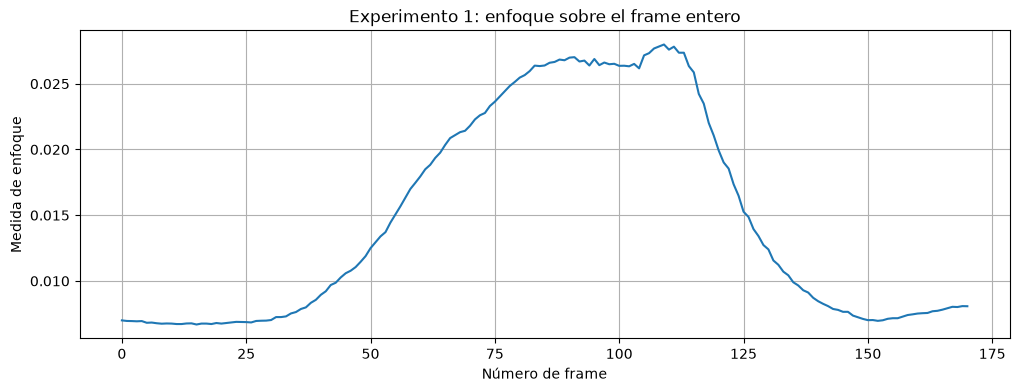

In [5]:
# Calculamos la medida de enfoque de cada frame del video (frame entero)
medidas_frame = [medida_enfoque(f) for f in frames]

# Curva: en X el número de frame, en Y qué tan nítido está
plt.figure(figsize=(12, 4))
plt.plot(medidas_frame)
plt.xlabel('Número de frame')
plt.ylabel('Medida de enfoque')
plt.title('Experimento 1: enfoque sobre el frame entero')
plt.grid(True)
plt.show()


Frame de máximo enfoque: 109
Zona de máximo enfoque: frames 80 a 115


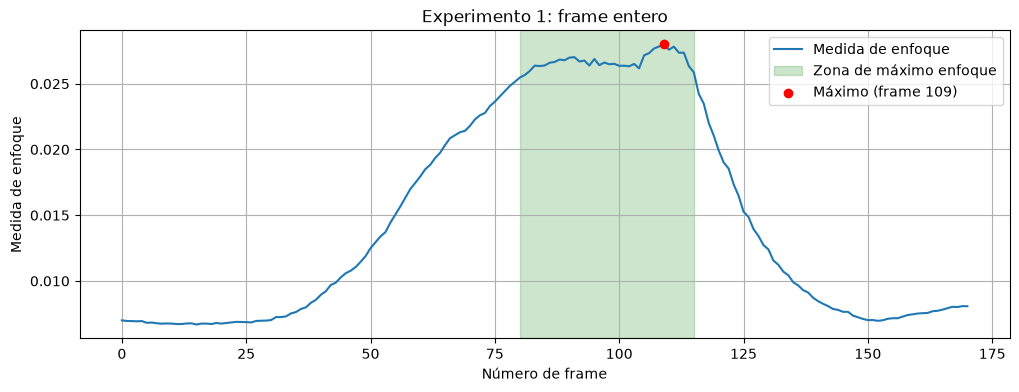

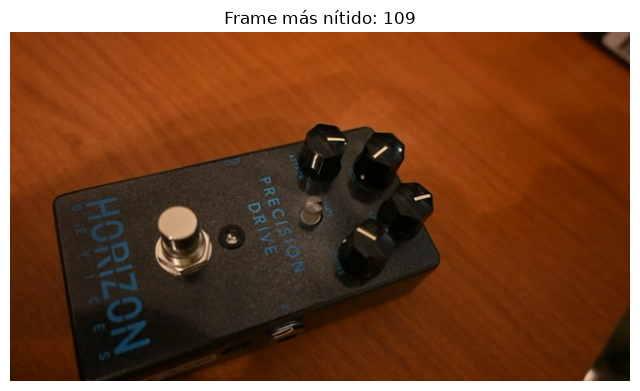

In [6]:
def detectar_enfoque(medidas, tolerancia=0.90):
    """Devuelve el frame más nítido y la lista de frames 'casi tan nítidos' (>= tolerancia * máximo)."""
    medidas = np.array(medidas)
    mejor = int(np.argmax(medidas))                                 # posición del valor más alto
    zona = np.where(medidas >= tolerancia * medidas.max())[0]       # frames cerca del máximo
    return mejor, zona

mejor_frame, zona_frame = detectar_enfoque(medidas_frame)
print('Frame de máximo enfoque:', mejor_frame)
print(f'Zona de máximo enfoque: frames {zona_frame.min()} a {zona_frame.max()}')

# Curva con la zona pintada y el máximo marcado
plt.figure(figsize=(12, 4))
plt.plot(medidas_frame, label='Medida de enfoque')
plt.axvspan(zona_frame.min(), zona_frame.max(), color='green', alpha=0.2, label='Zona de máximo enfoque')
plt.scatter(mejor_frame, medidas_frame[mejor_frame], color='red', zorder=3, label=f'Máximo (frame {mejor_frame})')
plt.xlabel('Número de frame')
plt.ylabel('Medida de enfoque')
plt.title('Experimento 1: frame entero')
plt.legend()
plt.grid(True)
plt.show()

# Mostramos el frame más nítido
plt.figure(figsize=(8, 5))
plt.imshow(cv.cvtColor(frames[mejor_frame], cv.COLOR_BGR2RGB))
plt.title(f'Frame más nítido: {mejor_frame}')
plt.axis('off')
plt.show()


Frame de máximo enfoque (ROI): 111
Zona de máximo enfoque (ROI): frames 101 a 113


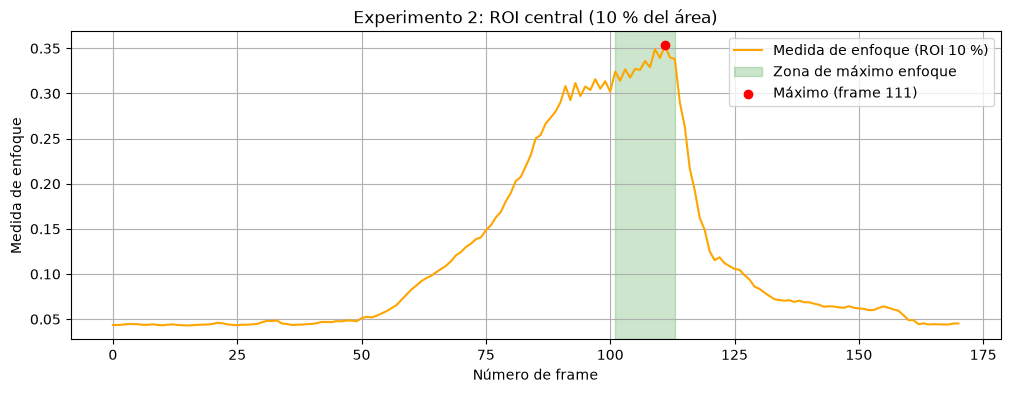

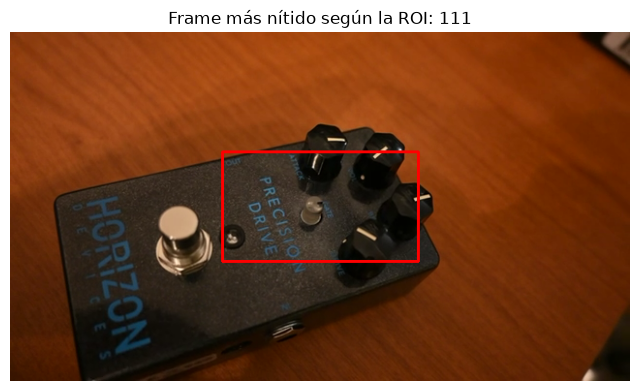

In [7]:
def recortar_roi(frame, fraccion_area=0.10):
    """Recorta un rectángulo centrado que ocupa 'fraccion_area' del área total del frame."""
    alto, ancho = frame.shape[:2]
    # Para que el área sea el 10 %, cada lado se achica por la raíz de 0,10 (≈ 0,316)
    escala = np.sqrt(fraccion_area)
    alto_roi, ancho_roi = int(alto * escala), int(ancho * escala)
    # Esquina superior izquierda del recuadro, para que quede centrado
    y0 = (alto - alto_roi) // 2
    x0 = (ancho - ancho_roi) // 2
    return frame[y0:y0 + alto_roi, x0:x0 + ancho_roi], (x0, y0, ancho_roi, alto_roi)

# Medimos la nitidez solo dentro del recuadro central, frame por frame
medidas_roi = [medida_enfoque(recortar_roi(f)[0]) for f in frames]
mejor_roi, zona_roi = detectar_enfoque(medidas_roi)
print('Frame de máximo enfoque (ROI):', mejor_roi)
print(f'Zona de máximo enfoque (ROI): frames {zona_roi.min()} a {zona_roi.max()}')

# Curva del experimento 2
plt.figure(figsize=(12, 4))
plt.plot(medidas_roi, color='orange', label='Medida de enfoque (ROI 10 %)')
plt.axvspan(zona_roi.min(), zona_roi.max(), color='green', alpha=0.2, label='Zona de máximo enfoque')
plt.scatter(mejor_roi, medidas_roi[mejor_roi], color='red', zorder=3, label=f'Máximo (frame {mejor_roi})')
plt.xlabel('Número de frame')
plt.ylabel('Medida de enfoque')
plt.title('Experimento 2: ROI central (10 % del área)')
plt.legend()
plt.grid(True)
plt.show()

# Frame más nítido con el recuadro dibujado encima
x0, y0, w, h = recortar_roi(frames[mejor_roi])[1]
con_recuadro = frames[mejor_roi].copy()
cv.rectangle(con_recuadro, (x0, y0), (x0 + w, y0 + h), (0, 0, 255), 2)   # rojo en BGR, grosor 2
plt.figure(figsize=(8, 5))
plt.imshow(cv.cvtColor(con_recuadro, cv.COLOR_BGR2RGB))
plt.title(f'Frame más nítido según la ROI: {mejor_roi}')
plt.axis('off')
plt.show()


### Conclusiones de los experimentos

**Métrica:** se implementó la medida del paper *Image Sharpness Measure for Blurred Images in Frequency Domain*. Se calcula la transformada de Fourier del frame en gris y se cuenta qué fracción de las frecuencias supera el valor máximo del espectro dividido 1000. Una imagen nítida tiene más detalle fino, o sea más frecuencias altas con peso, y da un valor mayor.

**Detección automática:** el algoritmo devuelve el frame con la medida más alta (máximo enfoque) y la zona de frames que están al 90 % o más de ese máximo.

| | Frame entero | ROI central (10 % del área) |
|---|---|---|
| Frame de máximo enfoque | 109 | 111 |
| Zona de máximo enfoque | 80 a 115 | 101 a 113 |

**Experimento 1 (frame entero):** la curva tiene forma de campana, con una meseta amplia en la cima. El máximo es claro, pero la zona de enfoque es ancha porque el fondo y los bordes de la imagen también aportan detalle aunque el centro todavía no esté del todo enfocado.

**Experimento 2 (ROI central):** el pico es más angosto y marcado, y la zona de máximo enfoque se reduce a pocos frames. Al medir solo el centro, que es donde está el objeto de interés, el detector es más preciso. Es el criterio que usan las cámaras con autofoco central.


Frames sobre el umbral SIN unsharp masking: 11 (frames 101 a 113)
Frames sobre el umbral CON unsharp masking: 39 (frames 79 a 117)


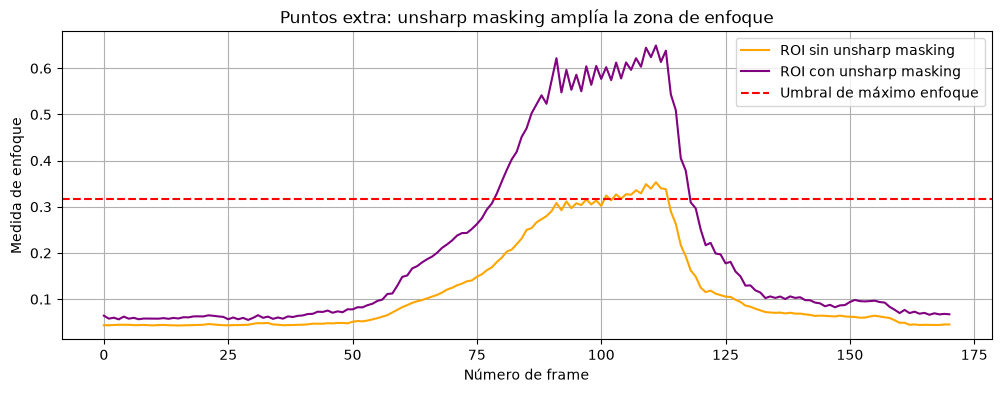

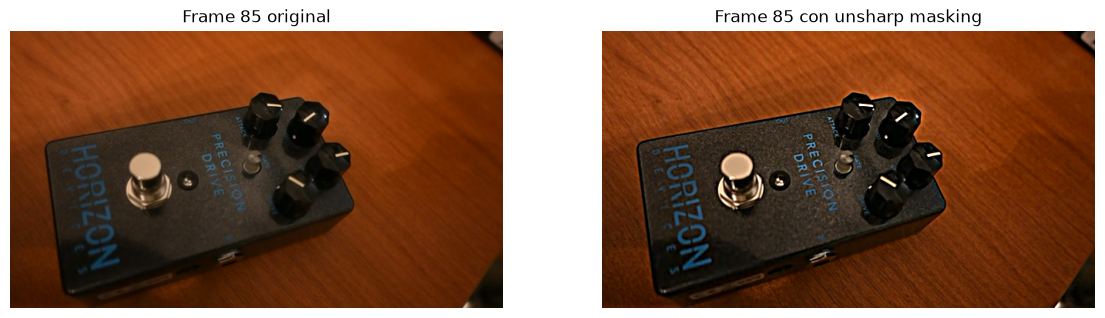

In [9]:
def unsharp_mask(frame, sigma=3, cantidad=1.5):
    """Realza bordes: original + cantidad * (original - versión borrosa)."""
    borrosa = cv.GaussianBlur(frame, (0, 0), sigma)            # copia desenfocada (sigma = cuánto desenfoca)
    # addWeighted calcula: (1 + cantidad)*original - cantidad*borrosa, cuidando el rango 0-255
    return cv.addWeighted(frame, 1 + cantidad, borrosa, -cantidad, 0)

# Medimos la ROI otra vez, pero sobre los frames con unsharp masking
medidas_usm = [medida_enfoque(recortar_roi(unsharp_mask(f))[0]) for f in frames]

# Usamos el MISMO umbral que en el experimento 2 (90 % del máximo original), para comparar justo
umbral = 0.90 * max(medidas_roi)
zona_antes = np.where(np.array(medidas_roi) >= umbral)[0]
zona_despues = np.where(np.array(medidas_usm) >= umbral)[0]
print(f'Frames sobre el umbral SIN unsharp masking: {len(zona_antes)} (frames {zona_antes.min()} a {zona_antes.max()})')
print(f'Frames sobre el umbral CON unsharp masking: {len(zona_despues)} (frames {zona_despues.min()} a {zona_despues.max()})')

# Las dos curvas juntas, con la línea del umbral
plt.figure(figsize=(12, 4))
plt.plot(medidas_roi, color='orange', label='ROI sin unsharp masking')
plt.plot(medidas_usm, color='purple', label='ROI con unsharp masking')
plt.axhline(umbral, color='red', linestyle='--', label='Umbral de máximo enfoque')
plt.xlabel('Número de frame')
plt.ylabel('Medida de enfoque')
plt.title('Puntos extra: unsharp masking amplía la zona de enfoque')
plt.legend()
plt.grid(True)
plt.show()

# Antes y después en un frame "casi enfocado" (el 85)
i = 85
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
ejes[0].imshow(cv.cvtColor(frames[i], cv.COLOR_BGR2RGB))
ejes[0].set_title(f'Frame {i} original')
ejes[1].imshow(cv.cvtColor(unsharp_mask(frames[i]), cv.COLOR_BGR2RGB))
ejes[1].set_title(f'Frame {i} con unsharp masking')
ejes[0].axis('off')
ejes[1].axis('off')
plt.show()


### Puntos extra: unsharp masking

Se aplicó *unsharp masking* a cada frame antes de medir la ROI central: `enfocada = original + 1,5 × (original − gaussiano(σ = 3))`. El filtro gaussiano es un pasa bajos, así que `original − gaussiano` aísla el detalle fino (los bordes), y sumarlo amplificado los realza.

Con el **mismo umbral** del experimento 2 (90 % del máximo original), la zona de máximo enfoque pasa de **11 frames (101 a 113)** a **39 frames (79 a 117)**. Los frames que estaban casi enfocados recuperan suficiente detalle fino para superar el umbral, y así se expande la zona de enfoque.

Hay un límite: el unsharp masking solo realza el detalle que todavía existe en la imagen. En los frames muy desenfocados no hay bordes para recuperar, y por eso la curva sigue baja en los extremos del video.


Frame de máximo enfoque (matriz): 91
Zona de máximo enfoque (matriz): frames 84 a 111


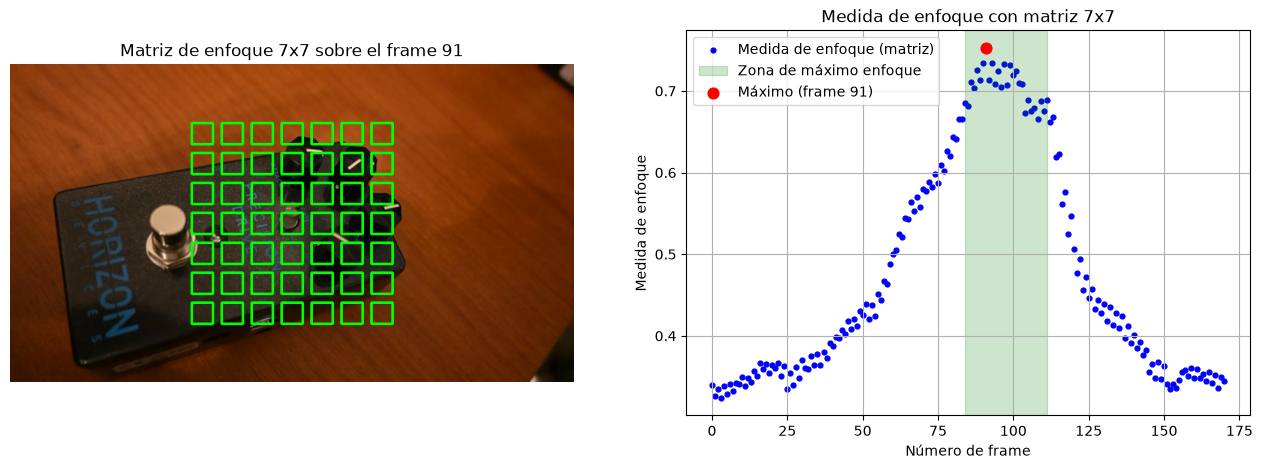

In [10]:
def armar_grilla(forma_frame, n=7, lado=24, separacion=10):
    """Posiciones (x, y, lado) de una grilla n x n de cuadraditos, centrada en el frame."""
    alto, ancho = forma_frame[:2]
    total = n * lado + (n - 1) * separacion                  # ancho total que ocupa la grilla
    x0, y0 = (ancho - total) // 2, (alto - total) // 2       # esquina para que quede centrada
    return [(x0 + j * (lado + separacion), y0 + i * (lado + separacion), lado)
            for i in range(n) for j in range(n)]

def medida_matriz(frame, grilla):
    """Nitidez de cada cuadradito con la métrica del paper, y su promedio."""
    return np.mean([medida_enfoque(frame[y:y + l, x:x + l]) for x, y, l in grilla])

# Armamos la grilla una vez (todos los frames tienen el mismo tamaño) y medimos el video
grilla = armar_grilla(frames[0].shape)
medidas_matriz = [medida_matriz(f, grilla) for f in frames]
mejor_mat, zona_mat = detectar_enfoque(medidas_matriz)
print('Frame de máximo enfoque (matriz):', mejor_mat)
print(f'Zona de máximo enfoque (matriz): frames {zona_mat.min()} a {zona_mat.max()}')

# Frame más nítido con la matriz dibujada (izquierda) y la curva (derecha), como en la diapositiva 20
con_matriz = frames[mejor_mat].copy()
for x, y, l in grilla:
    cv.rectangle(con_matriz, (x, y), (x + l, y + l), (0, 255, 0), 2)   # verde en BGR

fig, ejes = plt.subplots(1, 2, figsize=(16, 5))
ejes[0].imshow(cv.cvtColor(con_matriz, cv.COLOR_BGR2RGB))
ejes[0].set_title(f'Matriz de enfoque 7x7 sobre el frame {mejor_mat}')
ejes[0].axis('off')
ejes[1].scatter(range(len(medidas_matriz)), medidas_matriz, s=12, color='blue', label='Medida de enfoque (matriz)')
ejes[1].axvspan(zona_mat.min(), zona_mat.max(), color='green', alpha=0.2, label='Zona de máximo enfoque')
ejes[1].scatter(mejor_mat, medidas_matriz[mejor_mat], color='red', s=60, zorder=3, label=f'Máximo (frame {mejor_mat})')
ejes[1].set_xlabel('Número de frame')
ejes[1].set_ylabel('Medida de enfoque')
ejes[1].set_title('Medida de enfoque con matriz 7x7')
ejes[1].legend()
ejes[1].grid(True)
plt.show()


### Matriz de enfoque

Como muestra la diapositiva 20, se reemplazó la ROI única por una **matriz de 7 × 7 cuadraditos** de 24 × 24 píxeles, centrada en el frame. Se calcula la métrica del paper en cada cuadradito y se promedia: es el esquema de autofoco con múltiples puntos de medición de las cámaras digitales.

Resultado: máximo enfoque en el **frame 91**, con la zona de máximo enfoque entre los **frames 84 y 111**. La curva tiene la misma forma de campana que la de la diapositiva. El pico aparece antes que con la ROI única porque la matriz cubre un área más amplia del objeto y promedia 49 mediciones, lo que la hace menos sensible a un detalle puntual.
